In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from sklearn.datasets import make_classification
X,y = make_classification (n_samples=1000,
                          n_features=2,
                          n_informative=2,
                          n_redundant=0,
                          n_classes=2,
                          class_sep=2,
                          random_state=1)

In [ ]:
pd.DataFrame(X).head()

,0,1
0,1.863411,0.087646
1,-1.530997,1.901182
2,-0.017224,-2.591112
3,-2.032039,-1.801162
4,4.620555,0.901124


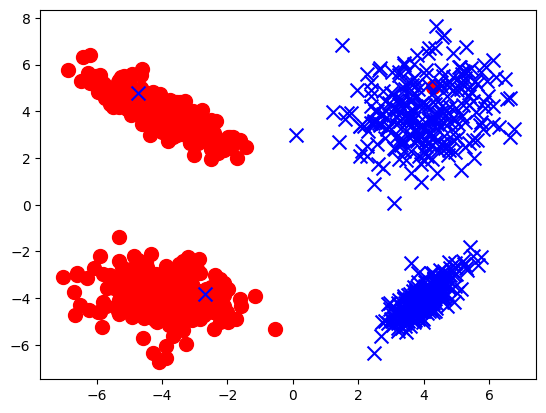

In [ ]:
plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
plt.show()

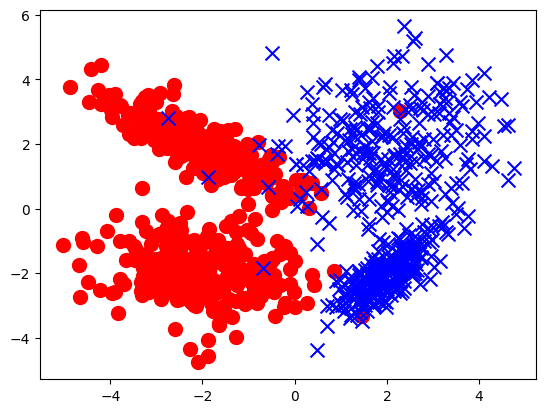

In [ ]:
plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
plt.show()

In [ ]:
class SGD():
    def __init__(self, alpha=0.5, n_iters=1000):
        self.b = None
        self._alpha = alpha
        self._n_iters = n_iters
    def gradient_step(self, b, b_grad):
        return b - self._alpha * b_grad
    def optimize(self, X, y, start_b, n_iters):
        b = start_b.copy()
        for i in range(n_iters):
          b_grad = self.grad_func(X, y, b)
          b = self.gradient_step(b, b_grad)
        return b
    def fit(self, X, y):
        m = X.shape[1]
        start_b = np.ones(m)
        self.b = self.optimize(X, y, start_b, self._n_iters)


In [ ]:
class LogReg(SGD):
    def sigmoid(self, X, b):
        return 1. / (1. + np.exp(-X.dot(b)))
    def grad_func(self, X, y, b):
        n = X.shape[0]
        grad = 1. / n * X.transpose().dot(self.sigmoid(X, b) - y)
        return grad
    def predict_proba(self, X):
        return self.sigmoid(X, self.b)

    def predict(self, X):
        y_pred = self.predict_proba(X) > 0.5
        return y_pred

In [ ]:
X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])

In [ ]:
logreg = LogReg()

In [ ]:
logreg.fit(X, y)
y_pred = logreg.predict(X)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
ac = accuracy_score(y, y_pred)
f1 = f1_score(y, y_pred)
print(f'accuracy = {ac:.2f} F1-score = {f1:.2f}')

accuracy = 1.00 F1-score = 1.00


In [ ]:
y_pred_proba = logreg.predict_proba(X)

In [ ]:
xx, yy = np.meshgrid(
    np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01),
    np.arange(X.min(axis=0)[2]-1, X.max(axis=0)[2]+1, 0.01))
XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
XX = np.array([(1, *xx) for xx in XX])

In [ ]:
Z = logreg.predict_proba(XX)
Z = Z.reshape(xx.shape)

Проверьте работу модели с другими значениями скорости обучения. Найдите значение, при котором градиентный спуск расходится.

Поэкспериментируйте с разными значениями параметра class_sep при генерации датасета. Визуализируйте полученные распределения. Сделайте вывод о том, как этот параметр влияет на точность получаемых моделей.

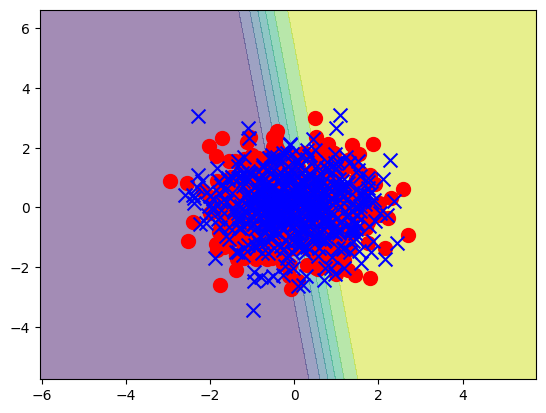

In [ ]:
plt.contourf(xx, yy, Z, alpha=0.5)
plt.scatter(X[:, 1][y==0], X[:, 2][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 1][y==1], X[:, 2][y==1], marker="x", c='b', s=100)

Можно сделать вывод о том, что чем выше значение разделяющего класса, тем ниже классификация модели.

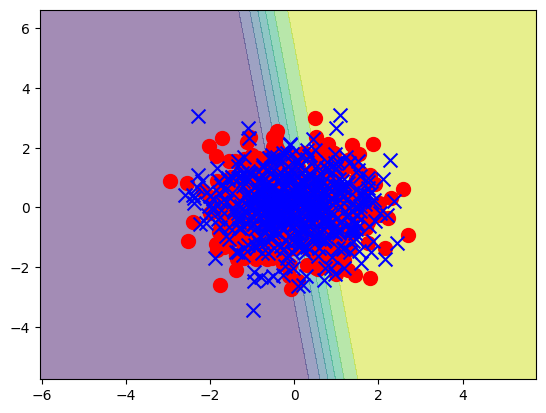

In [ ]:
plt.contourf(xx, yy, Z, alpha=0.5)
plt.scatter(X[:, 1][y==0], X[:, 2][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 1][y==1], X[:, 2][y==1], marker="x", c='b', s=100)

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [ ]:
model.fit(X, y)


LogisticRegression()

In [ ]:
y_pred_lr = model.predict(X)

Выведите результаты работы библиотечной модели - в численном и в графическом виде.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
mean_absolute_error(y, y_pred_lr)

0.024

In [ ]:
mean_squared_error(y, y_pred_lr)

0.024

In [ ]:
r2_score(y, y_pred_lr)

0.903999615998464

Сгенерируйте датасет с большим числом признаков и примените к нему созданную модель.

In [ ]:
X, y = make_classification(n_samples=1000, n_features=100, n_informative=10, n_redundant=10, random_state=42)

In [ ]:
model = LogReg()
model.fit(X, y)

In [ ]:
y_pred = model.predict(X)

In [ ]:
accuracy_score(y, y_pred)

0.869

In [ ]:
xx, yy = np.meshgrid(
    np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01),
    np.arange(X.min(axis=0)[2]-1, X.max(axis=0)[2]+1, 0.01))
XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
XX = np.array([(1, *xx) for xx in XX])

In [ ]:
Z = logreg.predict_proba(XX)
Z = Z.reshape(xx.shape)

TypeError: Shapes of x (854, 767) and z (1240, 1179) do not match

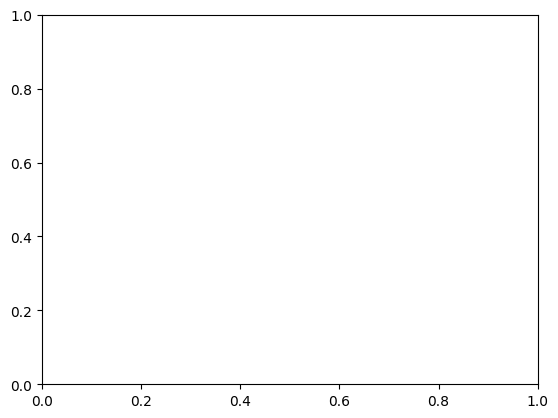

In [ ]:
plt.contourf(xx, yy, Z, alpha=0.5)
plt.scatter(X[:, 1][y==0], X[:, 2][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 1][y==1], X[:, 2][y==1], marker="x", c='b', s=100)

Сгенерируйте датасет с большим количеством классов и реализуйте в классе алгоритм "один против всех". Решите задачу множественной классификации средствами sklearn.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [ ]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=1000, n_features=20, n_classes=30, n_informative=10, n_redundant=5, random_state=42)

In [ ]:
X

array([[-0.35132836, -6.22716858, -1.7358135 , ..., -3.9808085 ,
        -0.46126708, -3.78924182],
       [-0.34188041,  1.69068694,  1.04140537, ..., -0.98506379,
         1.0081339 ,  0.19261969],
       [-0.46530184, -4.88811701,  0.75926918, ..., -0.88431507,
        -2.08944678,  2.01367907],
       ...,
       [ 0.31834121, -0.9983486 ,  0.33341025, ..., -4.21742969,
        -0.18751105, -0.61807058],
       [-0.70335563, -1.11112055, -2.77890182, ..., -2.62430497,
        -0.23674697,  1.34265345],
       [-0.47958208,  0.27964674, -1.19590137, ...,  2.77104862,
        -0.05442088,  0.03838422]])

In [ ]:
y

array([10, 22, 23, 11, 14,  7,  6,  1,  6, 28,  3, 12, 23, 20,  9,  4,  8,
       25, 25, 26, 13,  4,  5, 12, 19,  2, 13,  8, 20, 19,  4, 25, 21, 11,
        0,  4,  9, 25, 21, 17, 21, 17, 11, 27,  6, 22, 28, 19, 28, 16, 29,
       15,  8, 14, 11, 15,  7, 27,  4,  6, 18,  7, 23, 24, 24, 24, 14,  5,
       18,  3, 23,  2,  2, 14,  9,  7,  7,  3, 24, 15,  8, 24,  3, 28, 18,
        6, 20, 12,  6,  9,  2, 26, 23,  4, 16, 15, 18, 21,  9,  1,  0, 16,
       28, 20,  1, 18,  7, 29,  9, 15,  4, 22, 26,  3,  3, 12, 14,  7, 23,
        2, 19,  2, 11, 17, 27, 27,  2, 27, 16,  7, 24,  3,  9,  5,  9, 25,
        0, 22, 22, 19, 11, 11, 28,  9,  3,  5, 29, 21, 16, 20,  6, 13,  7,
        1, 15, 16, 29,  5,  8, 19, 15, 18,  6, 24,  5, 13, 15, 21, 13,  6,
       13, 13,  0,  0, 28,  8, 12, 18,  1, 22, 24,  3,  8, 12, 12, 21, 13,
        2, 22,  2,  7,  7, 14, 11, 20, 15, 20,  5, 17, 26, 29, 13,  7, 24,
       12, 24,  2, 19, 16,  5, 13, 27, 17, 27, 29, 21, 11, 14,  8,  4,  7,
        9, 26, 15,  5, 16

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = OneVsRestClassifier(LogisticRegression(max_iter=1000))

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
ac = accuracy_score(y_test, y_pred)


In [ ]:
ac

0.14333333333333334